# Escadas Rolantes: Manutenção Orientada por Dados
**Challenge Motiva + FIAP 2026/2027 · Dynamic Programming · Sprint 1**

Este notebook executa a solução do início ao fim:

1. **Preparação dos dados**: notas de falha da Motiva (últimos 12 meses)
2. **Degradação acumulada**: três versões (recursiva, memoizada, tabulação) e medição
3. **Ranking de criticidade** das escadas
4. **Rede de estações como grafo**: BFS, Dijkstra e A*
5. **Plano de manutenção**: `planejar_turno(base, horas)`

O código fica nos arquivos `degradacao.py`, `grafo.py` e `planejamento.py`; aqui eles são chamados e os resultados são interpretados.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

import degradacao as dg
import grafo as gr
import planejamento as pl

sys.setrecursionlimit(5000)
pd.set_option("display.width", 200)

## 1. Preparação dos dados

O dataset da Motiva (`dados/ecr_09-26.XLSX`, aba `ZMM_ANALISE_NOTAS`) **não traz leituras de sensores**: ele traz as **notas de manutenção** de cada escada. Usamos as notas do tipo **Z1 (falha)**.

- Cada falha é tratada como uma **leitura** da escada, em ordem de data.
- Janela: últimos 12 meses do dataset (a mesma usada pelo grupo de Data Science).
- `peso = 2` se a escada ficou indisponível na falha, `peso = 1` caso contrário.

Na primeira execução a planilha é lida e salva em `dados/falhas_12m.csv`; depois o CSV é reaproveitado.

In [2]:
falhas = dg.preparar_falhas()
leituras = dg.montar_leituras(falhas)

print(f"Falhas (Z1) nos últimos 12 meses: {len(falhas)}")
print(f"Escadas: {len(leituras)}")
print(f"Período: {falhas['data_hora'].min():%d/%m/%Y} a {falhas['data_hora'].max():%d/%m/%Y}")
falhas.head()

Falhas (Z1) nos últimos 12 meses: 8591
Escadas: 197
Período: 22/09/2025 a 22/09/2026


,id_escada,estacao,data_hora,peso
0,BUT-ER01,BUT,2025-09-22 14:08:01,2
1,BUT-ER01,BUT,2025-10-17 14:08:35,1
2,BUT-ER01,BUT,2025-11-10 05:40:32,1
3,BUT-ER01,BUT,2025-11-10 06:10:00,2
4,BUT-ER01,BUT,2025-11-11 05:27:44,2


## 2. Degradação acumulada com Programação Dinâmica

Para cada escada, `D(i)` é a degradação acumulada depois da leitura `i`:

```
D(0) = 0
D(1) = peso(1)
D(i) = D(i-1) + peso(i)                              se a falha não é reincidente
D(i) = D(i-1) + peso(i) + 0,5 · (D(i-1) − D(i-2))    se a falha é reincidente
```

- **Reincidente**: a falha aconteceu até 7 dias depois da anterior.
- `D(i-1) − D(i-2)` é o impacto da falha anterior. Se o problema voltou em menos de 7 dias, ele não foi resolvido, e a falha nova **herda metade** desse impacto.

Como `D(i)` depende de `D(i-1)` **e** de `D(i-2)` (como Fibonacci), existem **subproblemas sobrepostos**: é aí que a Programação Dinâmica ajuda.

### Exemplo pequeno, conferido à mão

| i | peso | reincidente | conta | D(i) |
|---|---|---|---|---|
| 1 | 1 | – | 1 | 1 |
| 2 | 2 | sim | 1 + 2 + 0,5·(1 − 0) | 3,5 |
| 3 | 1 | não | 3,5 + 1 | 4,5 |
| 4 | 1 | sim | 4,5 + 1 + 0,5·(4,5 − 3,5) | 6,0 |

In [3]:
pesos = [1, 2, 1, 1]
reinc = [False, True, False, True]

print("Recursiva :", dg.degradacao_recursiva(pesos, reinc, 4))
print("Memoizada :", dg.degradacao_memoizada(pesos, reinc, 4))
print("Tabulação :", dg.degradacao_tabular(pesos, reinc, 4)[0])
print("Tabela D  :", dg.degradacao_tabular(pesos, reinc, 4)[1])

Recursiva : 6.0
Memoizada : 6.0
Tabulação : 6.0
Tabela D  : [0.0, 1, 3.5, 4.5, 6.0]


### Medição das três versões

Usamos a escada com mais falhas no período e medimos as três versões para as primeiras `n` leituras. A recursiva pura só é medida até `n = 25`: depois disso ela fica lenta demais. O código confere que as três versões retornam o mesmo valor.

In [4]:
escada = max(leituras, key=lambda e: len(leituras[e][0]))
p, r = leituras[escada]
print(f"Escada usada na medição: {escada} ({len(p)} leituras)")

medicao = dg.comparar_versoes(p, r, [5, 10, 15, 20, 25, 50, 100, len(p)])
medicao

Escada usada na medição: LUZ-ER04 (147 leituras)


,n,degradacao,tempo_recursiva_ms,chamadas_recursiva,tempo_memoizada_ms,chamadas_memoizada,tempo_tabular_ms
0,5,13.25,0.0045,15.0,0.0041,9,0.0026
1,10,30.29,0.0465,177.0,0.0063,19,0.0031
2,15,48.07,0.5422,1973.0,0.0101,29,0.0042
3,20,68.00,5.9333,21891.0,0.0132,39,0.0053
4,25,88.00,40.8209,242785.0,0.0161,49,0.0072
5,50,179.00,NaN,NaN,0.0221,96,0.0096
6,100,374.02,NaN,NaN,0.0574,196,0.0187
7,147,537.52,NaN,NaN,0.0772,286,0.0218


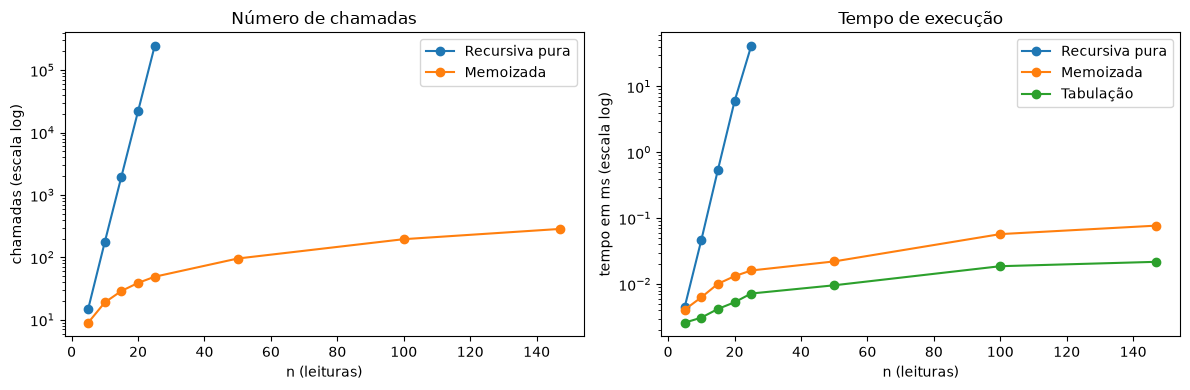

In [5]:
rec = medicao.dropna(subset=["chamadas_recursiva"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(rec["n"], rec["chamadas_recursiva"], "o-", label="Recursiva pura")
ax1.plot(medicao["n"], medicao["chamadas_memoizada"], "o-", label="Memoizada")
ax1.set_yscale("log")
ax1.set_xlabel("n (leituras)")
ax1.set_ylabel("chamadas (escala log)")
ax1.set_title("Número de chamadas")
ax1.legend()

ax2.plot(rec["n"], rec["tempo_recursiva_ms"], "o-", label="Recursiva pura")
ax2.plot(medicao["n"], medicao["tempo_memoizada_ms"], "o-", label="Memoizada")
ax2.plot(medicao["n"], medicao["tempo_tabular_ms"], "o-", label="Tabulação")
ax2.set_yscale("log")
ax2.set_xlabel("n (leituras)")
ax2.set_ylabel("tempo em ms (escala log)")
ax2.set_title("Tempo de execução")
ax2.legend()

plt.tight_layout()
plt.show()

**Interpretação**

- **Recursiva pura**: o número de chamadas cresce de forma **exponencial** (cerca de 11 vezes a cada 5 leituras a mais: 177 → 1.973 → 21.891 → 242.785). Ela recalcula `D(i-2)` várias vezes. Com as 147 leituras da escada, seria inviável.
- **Memoizada**: guarda cada `D(i)` num dicionário, então cada valor é calculado uma vez. O número de chamadas cresce de forma **linear** (cerca de 2·n).
- **Tabulação**: também é linear, mas sem o custo das chamadas recursivas e sem risco de estourar a pilha. É a mais rápida e foi a usada para gerar o ranking.
- As três versões dão **o mesmo resultado**: a otimização não muda o valor, só o custo.

## 3. Ranking de criticidade

A degradação final de cada escada (calculada com tabulação) define o ranking: quanto maior, mais crítica.

In [6]:
ranking = dg.gerar_ranking(leituras)
ranking.to_csv("ranking_criticidade.csv", index=False)
ranking.head(15)

,posicao,id_escada,estacao,falhas_12m,reincidentes,degradacao
0,1,LUZ-ER04,LUZ,147,139,537.52
1,2,VSO-ER08,VSO,136,127,500.50
2,3,PIN-ER28,PIN,138,125,496.12
3,4,PIN-ER24,PIN,131,121,473.00
4,5,PTA-ER17,PTA,127,113,431.87
5,6,PIN-ER32,PIN,121,105,413.93
6,7,PIN-ER31,PIN,107,99,382.67
7,8,HIG-ER22,HIG,109,95,372.07
8,9,FRE-ER13,FRE,105,92,369.76
9,10,REP-ER59,REP,98,86,342.81


In [7]:
print("Escadas por estação no top 15:")
print(ranking.head(15)["estacao"].value_counts().to_string())

corr = ranking[["degradacao", "falhas_12m"]].corr(method="spearman").iloc[0, 1]
print(f"\nCorrelação (Spearman) entre degradação e número de falhas: {corr:.2f}")

Escadas por estação no top 15:
estacao
PIN    6
VSO    2
LUZ    1
PTA    1
HIG    1
FRE    1
REP    1
FAL    1
BUT    1

Correlação (Spearman) entre degradação e número de falhas: 1.00


**Interpretação**

- **Pinheiros** concentra o maior número de escadas no topo do ranking. É também a estação com mais escadas da linha (32) e uma das mais movimentadas, por ser integração com a CPTM.
- A degradação acompanha de perto o **número de falhas** (correlação próxima de 1). Isso acontece porque a reincidência em até 7 dias é comum em quase todas as escadas, então ela aumenta a degradação de todas de forma parecida. Testamos janelas de 1 e 2 dias e o ranking quase não mudou.
- Ou seja: neste dataset, **o volume de falhas é o que mais pesa na criticidade**; a reincidência e a indisponibilidade ajustam a ordem entre escadas com número de falhas parecido.

## 4. Rede de estações como grafo

A rede está em `rede/rede_estacoes.json`:

- **Vértices**: as 11 estações da Linha 4-Amarela, o Terminal Vila Sônia (`TVS`) e a base de manutenção (Pátio Vila Sônia). As siglas são as mesmas do dataset, então cada escada se liga à sua estação pelo próprio código (`PIN-ER24` → `PIN`).
- **Arestas**: trechos com peso em minutos. Tempos estimados pelo grupo: trem entre estações, a pé até a base e dois trechos de **viatura** (base → Butantã e base → Pinheiros), já que a equipe também pode ir de carro.
- O grafo é guardado como **lista de adjacência**: `{estação: {vizinho: minutos}}`.

In [8]:
for estacao, vizinhos in gr.GRAFO.items():
    print(f"{estacao:>5}: {vizinhos}")

 BASE: {'VSO': 5, 'BUT': 18, 'PIN': 22}
  TVS: {'VSO': 3}
  VSO: {'BASE': 5, 'TVS': 3, 'MBI': 3}
  MBI: {'VSO': 3, 'BUT': 3}
  BUT: {'MBI': 3, 'PIN': 2, 'BASE': 18}
  PIN: {'BUT': 2, 'FAL': 2, 'BASE': 22}
  FAL: {'PIN': 2, 'FRA': 2}
  FRA: {'FAL': 2, 'FRE': 2}
  FRE: {'FRA': 2, 'PTA': 2}
  PTA: {'FRE': 2, 'HIG': 2}
  HIG: {'PTA': 2, 'REP': 2}
  REP: {'HIG': 2, 'LUZ': 2}
  LUZ: {'REP': 2}


### BFS × Dijkstra, saindo da base

- **BFS** encontra o caminho com **menos trechos** (não olha o tempo).
- **Dijkstra** encontra o caminho de **menor tempo**.

In [9]:
tempos, anterior, _ = gr.dijkstra(gr.BASE)
linhas = []
for est in gr.GRAFO:
    if est == gr.BASE:
        continue
    r_bfs = gr.bfs(gr.BASE, est)
    r_dij = gr.reconstruir_rota(anterior, est)
    linhas.append({
        "destino": est,
        "BFS_trechos": len(r_bfs) - 1,
        "BFS_min": gr.tempo_da_rota(r_bfs),
        "Dijkstra_trechos": len(r_dij) - 1,
        "Dijkstra_min": tempos[est],
        "rota_Dijkstra": " > ".join(r_dij),
    })
pd.DataFrame(linhas)

,destino,BFS_trechos,BFS_min,Dijkstra_trechos,Dijkstra_min,rota_Dijkstra
0,TVS,2,8,2,8,BASE > VSO > TVS
1,VSO,1,5,1,5,BASE > VSO
2,MBI,2,8,2,8,BASE > VSO > MBI
3,BUT,1,18,3,11,BASE > VSO > MBI > BUT
4,PIN,1,22,4,13,BASE > VSO > MBI > BUT > PIN
5,FAL,2,24,5,15,BASE > VSO > MBI > BUT > PIN > FAL
6,FRA,3,26,6,17,BASE > VSO > MBI > BUT > PIN > FAL > FRA
7,FRE,4,28,7,19,BASE > VSO > MBI > BUT > PIN > FAL > FRA > FRE
8,PTA,5,30,8,21,BASE > VSO > MBI > BUT > PIN > FAL > FRA > FRE...
9,HIG,6,32,9,23,BASE > VSO > MBI > BUT > PIN > FAL > FRA > FRE...


**Interpretação**: até Morumbi as duas rotas são iguais. A partir de Butantã, o BFS escolhe a **viatura** (1 trecho, mas 18 a 22 min) e o Dijkstra escolhe o **trem** (mais trechos, porém mais rápido). Para chegar a Luz, o caminho do Dijkstra tem 11 trechos e leva 27 min; o do BFS tem 8 trechos e leva 36 min. Para planejar a manutenção, o que importa é o **tempo**, então usamos o Dijkstra.

### A* × Dijkstra

O A* ordena a fila por `tempo até aqui + h(n)`, onde a heurística é:

```
h(n) = distância em linha reta até o destino / velocidade do trecho mais rápido da rede
```

**Por que a heurística é válida (admissível):** nenhum caminho real é mais curto que a linha reta, e nenhum trecho é mais rápido que a maior velocidade da rede. Então `h(n)` **nunca passa** do tempo real que falta, e o A* sempre encontra o mesmo tempo ótimo do Dijkstra.

Comparamos saindo de **Paulista** (meio da linha), que é a situação do turno: a equipe sai de uma escada para a próxima.

In [10]:
print(f"Velocidade do trecho mais rápido: {gr.VELOCIDADE_MAXIMA:.2f} km/min")

linhas = []
for est in gr.GRAFO:
    if est == "PTA":
        continue
    t_dij, _, vis_dij = gr.dijkstra("PTA", est)
    t_astar, rota, vis_astar = gr.astar("PTA", est)
    assert t_astar == t_dij[est]
    linhas.append({"destino": est, "tempo_min": t_astar,
                   "visitados_Dijkstra": vis_dij, "visitados_A*": vis_astar})

comparacao = pd.DataFrame(linhas)
print(comparacao.to_string(index=False))
print(f"\nTOTAL visitados: Dijkstra = {comparacao['visitados_Dijkstra'].sum()}"
      f" | A* = {comparacao['visitados_A*'].sum()}")

Velocidade do trecho mais rápido: 0.72 km/min
destino  tempo_min  visitados_Dijkstra  visitados_A*
   BASE         21                  13            12
    TVS         19                  12            10
    VSO         16                  11             8
    MBI         13                  10             7
    BUT         10                   9             6
    PIN          8                   8             5
    FAL          6                   6             4
    FRA          4                   4             3
    FRE          2                   2             2
    HIG          2                   3             2
    REP          4                   5             3
    LUZ          6                   7             4

TOTAL visitados: Dijkstra = 90 | A* = 66


**Interpretação**: o A* encontrou **o mesmo tempo** que o Dijkstra em todos os destinos, mas visitou **menos estações** (66 contra 90, cerca de 27% a menos). O Dijkstra expande para os dois lados da linha; o A* é puxado pela heurística na direção do destino. Saindo da base, que fica numa ponta da linha, a vantagem é pequena, porque quase todas as estações já estão "no caminho". Em uma rede maior, com várias linhas, a economia seria maior.

## 5. Plano de manutenção: `planejar_turno(base, horas)`

Algoritmo guloso:

1. A equipe sai da base.
2. Percorre o ranking da escada mais crítica para a menos crítica.
3. Para cada escada soma: ida **da posição atual** até a estação (Dijkstra) + 30 min de manutenção + volta da estação até a base.
4. Se couber no turno, a escada entra no plano e a equipe passa a estar naquela estação; se não, pula para a próxima.
5. No fim, a equipe volta para a base.

O tempo de volta é reservado antes de aceitar cada escada, então a equipe nunca fica sem tempo de voltar.

In [11]:
plano, usado = pl.planejar_turno(gr.BASE, 8)
pl.imprimir_plano(plano, usado, 8)

=== PLANO DO TURNO (8 h = 480 min) ===
 1. LUZ-ER04 (Luz) | degradação 537.52 | deslocamento 27 min + manutenção 30 min | BASE > VSO > MBI > BUT > PIN > FAL > FRA > FRE > PTA > HIG > REP > LUZ
 2. VSO-ER08 (Vila Sonia) | degradação 500.5 | deslocamento 22 min + manutenção 30 min | LUZ > REP > HIG > PTA > FRE > FRA > FAL > PIN > BUT > MBI > VSO
 3. PIN-ER28 (Pinheiros) | degradação 496.12 | deslocamento 8 min + manutenção 30 min | VSO > MBI > BUT > PIN
 4. PIN-ER24 (Pinheiros) | degradação 473.0 | deslocamento 0 min + manutenção 30 min | (mesma estação)
 5. PTA-ER17 (Paulista) | degradação 431.87 | deslocamento 8 min + manutenção 30 min | PIN > FAL > FRA > FRE > PTA
 6. PIN-ER32 (Pinheiros) | degradação 413.93 | deslocamento 8 min + manutenção 30 min | PTA > FRE > FRA > FAL > PIN
 7. PIN-ER31 (Pinheiros) | degradação 382.67 | deslocamento 0 min + manutenção 30 min | (mesma estação)
 8. HIG-ER22 (Higienopolis-Mackenzie) | degradação 372.07 | deslocamento 10 min + manutenção 30 min | PIN 

In [12]:
plano4, usado4 = pl.planejar_turno(gr.BASE, 4)
pl.imprimir_plano(plano4, usado4, 4)

=== PLANO DO TURNO (4 h = 240 min) ===
 1. LUZ-ER04 (Luz) | degradação 537.52 | deslocamento 27 min + manutenção 30 min | BASE > VSO > MBI > BUT > PIN > FAL > FRA > FRE > PTA > HIG > REP > LUZ
 2. VSO-ER08 (Vila Sonia) | degradação 500.5 | deslocamento 22 min + manutenção 30 min | LUZ > REP > HIG > PTA > FRE > FRA > FAL > PIN > BUT > MBI > VSO
 3. PIN-ER28 (Pinheiros) | degradação 496.12 | deslocamento 8 min + manutenção 30 min | VSO > MBI > BUT > PIN
 4. PIN-ER24 (Pinheiros) | degradação 473.0 | deslocamento 0 min + manutenção 30 min | (mesma estação)
 5. PTA-ER17 (Paulista) | degradação 431.87 | deslocamento 8 min + manutenção 30 min | PIN > FAL > FRA > FRE > PTA
 6. Retorno à base | 21 min | PTA > FRE > FRA > FAL > PIN > BUT > MBI > VSO > BASE

Escadas atendidas: 5
Tempo em manutenção: 150 min
Tempo em deslocamento: 86 min
Total usado: 236 de 240 min


**Interpretação**

- Em 8 horas a equipe atende as **12 escadas mais críticas** e usa quase todo o turno (478 de 480 min): 360 min de manutenção e 118 min de deslocamento.
- Escadas da mesma estação são atendidas em sequência sem deslocamento (Pinheiros aparece várias vezes com 0 min).
- **Limitação**: seguir o ranking à risca às vezes faz a equipe atravessar a linha (Luz → Vila Sônia, 22 min) só porque a próxima escada mais crítica está do outro lado. Escolhemos dar **prioridade à criticidade**, não à distância.
- **Melhoria futura**: entre escadas com criticidade parecida, escolher a mais próxima da posição atual.

## Conclusões

- A Programação Dinâmica transformou um cálculo exponencial em linear, sem mudar o resultado.
- O ranking mostra que o volume de falhas é o principal fator de criticidade, com Pinheiros concentrando as escadas mais críticas.
- Dijkstra é o algoritmo certo para planejar o deslocamento (menor tempo); o A* chega ao mesmo resultado visitando menos estações.
- O `planejar_turno` junta as duas partes e gera um plano executável, respeitando o tempo do turno.